In [8]:
import os
import json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.0+cpu
Device: cpu


In [9]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

MODELS_DIR = PROJECT_ROOT / "models"
IMPROVEMENT_MODELS_DIR = MODELS_DIR / "improvement"

RESULTS_DIR = PROJECT_ROOT / "results"
IMPROVEMENT_RESULTS_DIR = RESULTS_DIR / "improvement"

DATA_DIR = PROJECT_ROOT / "data"

CHECKPOINT_PATH = (
    IMPROVEMENT_MODELS_DIR
    / "best_joint_finetuned_attention_fusion_fixed.pth"
)

MODEL_300_PATH = (
    IMPROVEMENT_MODELS_DIR
    / "best_joint_attention_300x300.pth"
)

print("Project root:", PROJECT_ROOT)
print("Final model:", CHECKPOINT_PATH)
print("Final model exists:", CHECKPOINT_PATH.exists())
print("300x300 model exists:", MODEL_300_PATH.exists())

Project root: d:\downloads\project\Diabetic-Retinopathy-Screening-Project
Final model: d:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\improvement\best_joint_finetuned_attention_fusion_fixed.pth
Final model exists: True
300x300 model exists: True


In [10]:
class JointAttentionFusionModel(nn.Module):

    def __init__(
        self,
        resnet_features,
        efficientnet_features,
        efficientnet_pool,
        num_classes=5
    ):
        super().__init__()

        self.resnet_features = resnet_features
        self.efficientnet_features = efficientnet_features
        self.efficientnet_pool = efficientnet_pool

        self.resnet_projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.efficientnet_projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        r_feat = self.resnet_features(x)
        r_feat = torch.flatten(r_feat, 1)
        r_proj = self.resnet_projection(r_feat)

        e_feat = self.efficientnet_features(x)
        e_feat = self.efficientnet_pool(e_feat)
        e_feat = torch.flatten(e_feat, 1)
        e_proj = self.efficientnet_projection(e_feat)

        combined = torch.cat([r_proj, e_proj], dim=1)

        attn_logits = self.attention(combined)
        attn_weights = torch.softmax(attn_logits, dim=1)

        fused = (
            attn_weights[:, 0:1] * r_proj
            + attn_weights[:, 1:2] * e_proj
        )

        out = self.classifier(fused)

        return out, attn_weights

In [11]:
resnet_raw = models.resnet18(weights=None)

resnet_raw.fc = nn.Linear(
    resnet_raw.fc.in_features,
    5
)

effnet_raw = models.efficientnet_b0(weights=None)

effnet_raw.classifier[1] = nn.Linear(
    effnet_raw.classifier[1].in_features,
    5
)

res_features = nn.Sequential(
    *list(resnet_raw.children())[:-1]
)

eff_features = effnet_raw.features

eff_pool = nn.AdaptiveAvgPool2d((1, 1))

print("Backbones reconstructed.")

Backbones reconstructed.


In [12]:
joint_model = JointAttentionFusionModel(
    resnet_features=res_features,
    efficientnet_features=eff_features,
    efficientnet_pool=eff_pool,
    num_classes=5
).to(device)

print("Joint model created.")

Joint model created.


In [13]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded.")
print("Checkpoint keys:")
print(checkpoint.keys())

Checkpoint loaded.
Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'best_val_qwk', 'best_val_loss', 'epochs_no_improve', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_qwk'])


In [15]:
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)
else:
    print("Checkpoint is not a dictionary.")

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - scaler_state_dict
 - history
 - best_val_qwk
 - best_val_loss
 - epochs_no_improve
 - val_loss
 - val_accuracy
 - val_macro_f1
 - val_qwk


In [16]:
dummy_input = torch.randn(
    2, 3, 224, 224,
    device=device
)

with torch.no_grad():
    dummy_logits, dummy_attention = joint_model(dummy_input)

print("Logits shape:", dummy_logits.shape)
print("Attention shape:", dummy_attention.shape)
print("Attention weights:")
print(dummy_attention)

print(
    "Attention row sums:",
    dummy_attention.sum(dim=1)
)

Logits shape: torch.Size([2, 5])
Attention shape: torch.Size([2, 2])
Attention weights:
tensor([[0.6288, 0.3712],
        [0.6435, 0.3565]])
Attention row sums: tensor([1.0000, 1.0000])


In [17]:
RESULTS_DIR = PROJECT_ROOT / "results" / "improvement"

print("Results directory:")
print(RESULTS_DIR)

print("\nExists:", RESULTS_DIR.exists())

Results directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement

Exists: True


In [19]:
validation_labels = np.load(
    RESULTS_DIR / "validation_labels.npy"
)

print("Validation labels shape:", validation_labels.shape)
print("Number of validation samples:", len(validation_labels))
print("Classes:", np.unique(validation_labels))

Validation labels shape: (6092,)
Number of validation samples: 6092
Classes: [0 1 2 3 4]


In [20]:
normal_probs = np.load(
    RESULTS_DIR / "normal_224_probabilities.npy"
)

print("Normal probability shape:", normal_probs.shape)
print("Probability sums, first 5:")
print(normal_probs[:5].sum(axis=1))

Normal probability shape: (6092, 5)
Probability sums, first 5:
[1. 1. 1. 1. 1.]


In [21]:
tta_probs = np.load(
    RESULTS_DIR / "horizontal_flip_tta_probabilities.npy"
)

print("TTA probability shape:", tta_probs.shape)
print("Probability sums, first 5:")
print(tta_probs[:5].sum(axis=1))

TTA probability shape: (6092, 5)
Probability sums, first 5:
[1.     1.     1.001  1.     0.9995]


In [22]:
with open(
    RESULTS_DIR / "optimized_thresholds.json",
    "r"
) as f:
    best_thresholds = json.load(f)

print("Frozen validation thresholds:")
print(best_thresholds)

Frozen validation thresholds:
{'thresholds': [0.8999999999999999, 1.6500000000000006, 2.6999999999999975, 3.599999999999998], 'validation_qwk': 0.8208033956648957, 'default_thresholds': [0.5, 1.5, 2.5, 3.5], 'default_qwk': 0.7428363421584598}


In [23]:
expected_severity = np.load(
    RESULTS_DIR / "expected_severity_tta.npy"
)

print("Expected severity shape:", expected_severity.shape)
print(expected_severity[:10])

Expected severity shape: (6092,)
[0.05824959 0.50800705 0.54480457 0.88473892 3.68374634 0.70236492
 1.18054199 0.24119925 3.07347107 0.05557847]


In [24]:
threshold_predictions = np.load(
    RESULTS_DIR / "threshold_optimized_predictions.npy"
)

print(
    "Threshold prediction shape:",
    threshold_predictions.shape
)

print(
    "Unique predictions:",
    np.unique(threshold_predictions)
)

Threshold prediction shape: (6092,)
Unique predictions: [0 1 2 3 4]


In [26]:
print("Type:", type(best_thresholds))
print("Value:")
print(best_thresholds)

Type: <class 'dict'>
Value:
{'thresholds': [0.8999999999999999, 1.6500000000000006, 2.6999999999999975, 3.599999999999998], 'validation_qwk': 0.8208033956648957, 'default_thresholds': [0.5, 1.5, 2.5, 3.5], 'default_qwk': 0.7428363421584598}


In [27]:
# Extract the actual threshold list from the saved JSON
if isinstance(best_thresholds, dict):

    if "thresholds" in best_thresholds:
        best_thresholds = best_thresholds["thresholds"]

    elif "best_thresholds" in best_thresholds:
        best_thresholds = best_thresholds["best_thresholds"]

    else:
        raise KeyError(
            f"Could not find threshold list. Available keys: "
            f"{list(best_thresholds.keys())}"
        )

best_thresholds = np.asarray(
    best_thresholds,
    dtype=np.float64
).flatten()

print("Frozen thresholds:", best_thresholds)
print("Shape:", best_thresholds.shape)

Frozen thresholds: [0.9  1.65 2.7  3.6 ]
Shape: (4,)


In [28]:
def apply_thresholds(severity, thresholds):
    thresholds = np.asarray(
        thresholds,
        dtype=np.float64
    ).flatten()

    return np.digitize(
        severity,
        thresholds
    )


recreated_threshold_predictions = apply_thresholds(
    expected_severity,
    best_thresholds
)

print(
    "Predictions identical:",
    np.array_equal(
        recreated_threshold_predictions,
        threshold_predictions
    )
)

Predictions identical: True


In [29]:
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)

    print("\nPossible weight containers:")
    for key in ["model", "state_dict", "model_state_dict", "weights"]:
        print(f"{key}: {key in checkpoint}")

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - scaler_state_dict
 - history
 - best_val_qwk
 - best_val_loss
 - epochs_no_improve
 - val_loss
 - val_accuracy
 - val_macro_f1
 - val_qwk

Possible weight containers:
model: False
state_dict: False
model_state_dict: True
weights: False


In [30]:
joint_model.eval()

print("✅ Final joint model is ready for inference")

✅ Final joint model is ready for inference


In [31]:
dummy_input = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    logits, attention = joint_model(dummy_input)

print("Logits shape:", logits.shape)
print("Attention shape:", attention.shape)
print("Attention sums:", attention.sum(dim=1))

Logits shape: torch.Size([2, 5])
Attention shape: torch.Size([2, 2])
Attention sums: tensor([1., 1.])


In [33]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score
)

NUM_CLASSES = 5

def evaluate_predictions(y_true, probs, predictions=None):

    y_true = np.asarray(y_true)

    probs = np.asarray(
        probs,
        dtype=np.float64
    )

    # Make sure every probability row sums to 1
    probs = probs / np.clip(
        probs.sum(axis=1, keepdims=True),
        1e-12,
        None
    )

    if predictions is None:
        predictions = np.argmax(probs, axis=1)

    predictions = np.asarray(predictions)

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true, predictions
    )

    results["Balanced Accuracy"] = balanced_accuracy_score(
        y_true, predictions
    )

    results["Macro Precision"] = precision_score(
        y_true, predictions,
        average="macro",
        zero_division=0
    )

    results["Macro Recall"] = recall_score(
        y_true, predictions,
        average="macro",
        zero_division=0
    )

    results["Macro F1"] = f1_score(
        y_true, predictions,
        average="macro",
        zero_division=0
    )

    results["Weighted F1"] = f1_score(
        y_true, predictions,
        average="weighted",
        zero_division=0
    )

    results["QWK"] = cohen_kappa_score(
        y_true,
        predictions,
        weights="quadratic"
    )

    results["Cohen Kappa"] = cohen_kappa_score(
        y_true,
        predictions
    )

    results["MCC"] = matthews_corrcoef(
        y_true,
        predictions
    )

    results["Log Loss"] = log_loss(
        y_true,
        probs,
        labels=np.arange(NUM_CLASSES)
    )

    try:
        results["ROC-AUC"] = roc_auc_score(
            y_true,
            probs,
            multi_class="ovr",
            average="macro"
        )
    except Exception as e:
        results["ROC-AUC"] = np.nan
        print("ROC-AUC could not be calculated:", e)

    return results

In [34]:
tta_predictions = np.argmax(tta_probs, axis=1)

tta_metrics = evaluate_predictions(
    validation_labels,
    tta_probs,
    tta_predictions
)

threshold_metrics = evaluate_predictions(
    validation_labels,
    tta_probs,
    recreated_threshold_predictions
)

normal_metrics = evaluate_predictions(
    validation_labels,
    normal_probs
)

comparison = pd.DataFrame(
    {
        "224 Normal": normal_metrics,
        "224 Horizontal Flip TTA": tta_metrics,
        "TTA + Frozen Thresholds": threshold_metrics
    }
)

comparison

,224 Normal,224 Horizontal Flip TTA,TTA + Frozen Thresholds
Accuracy,0.753447,0.769370,0.763953
Balanced Accuracy,0.761328,0.778770,0.654941
Macro Precision,0.645937,0.660672,0.673943
Macro Recall,0.761328,0.778770,0.654941
Macro F1,0.676425,0.693175,0.635359
Weighted F1,0.777955,0.791591,0.782723
QWK,0.767967,0.784102,0.820803
Cohen Kappa,0.545016,0.569990,0.520377
MCC,0.562048,0.585623,0.527584
Log Loss,0.634984,0.615338,0.615338


In [35]:
from pathlib import Path

print("Project root:")
print(PROJECT_ROOT)

print("\nData directory:")
print(DATA_DIR)

print("\nData contents:")
for p in DATA_DIR.iterdir():
    print(p)

Project root:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project

Data directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data

Data contents:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\interim
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\metadata
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\processed
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\raw


In [36]:
metadata_candidates = list(
    DATA_DIR.rglob("corrected_unified_metadata.csv")
)

print("Metadata files found:")
for p in metadata_candidates:
    print(p)

Metadata files found:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\metadata\corrected_unified_metadata.csv


In [37]:
image_files = list(
    DATA_DIR.rglob("*.jpg")
)

print("JPG images found:", len(image_files))

JPG images found: 46597


In [38]:
# ============================================================
# LOAD CORRECTED METADATA AND RECREATE EXACT PROJECT SPLIT
# ============================================================

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "metadata"
    / "corrected_unified_metadata.csv"
)

df = pd.read_csv(
    METADATA_PATH,
    low_memory=False
)

print("Metadata shape:", df.shape)
print("Metadata path:", METADATA_PATH)

Metadata shape: (40613, 46)
Metadata path: d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\metadata\corrected_unified_metadata.csv


In [39]:
# Keep only rows eligible for model training/evaluation
model_df = df[
    df["eligible_for_model"] == True
].copy()

# EXACT split used in Notebook 12
train_df = (
    model_df[model_df["model_split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    model_df[model_df["model_split"] == "val"]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    model_df[model_df["model_split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

print(f"Train: {len(train_df)}")
print(f"Val:   {len(val_df)}")
print(f"Test:  {len(test_df)}")
print(f"Total: {len(train_df) + len(val_df) + len(test_df)}")

Train: 28429
Val:   6092
Test:  6092
Total: 40613


In [40]:
print(
    "Test class distribution:"
)

print(
    test_df["label_dr_standard"]
    .value_counts()
    .sort_index()
)

Test class distribution:
label_dr_standard
0    4295
1     463
2    1001
3     174
4     159
Name: count, dtype: int64


In [41]:
print(
    "Missing test labels:",
    test_df["label_dr_standard"].isna().sum()
)

Missing test labels: 0


In [42]:
# ============================================================
# FIND IMAGE ROOT
# ============================================================

all_jpgs = list(DATA_DIR.rglob("*.jpg"))

print("Total JPG files:", len(all_jpgs))

# Show a few examples
for p in all_jpgs[:10]:
    print(p)

Total JPG files: 46597
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\Online-Challenge1&2-Evaluation\Images\347\347_l1.jpg
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\Online-Challenge1&2-Evaluation\Images\347\347_l2.jpg
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\Online-Challenge1&2-Evaluation\Images\347\347_r1.jpg
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\Online-Challenge1&2-Evaluation\Images\347\347_r2.jpg
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\Online-Challenge1&2-Evaluation\Images\353\353_l1.jpg
d:\downloads\project\Diabetic-Retinopathy-Screening-

In [43]:
print(
    test_df["processed_path"]
    .head(10)
    .to_string(index=False)
)

data/processed/images/aptos/aptos__d57e3b219a02...
data/processed/images/eyepacs/eyepacs__74bb29fc...
data/processed/images/eyepacs/eyepacs__49c0f361...
data/processed/images/eyepacs/eyepacs__93dc1a27...
data/processed/images/eyepacs/eyepacs__37c1fed4...
data/processed/images/eyepacs/eyepacs__81aa5398...
data/processed/images/eyepacs/eyepacs__2033f392...
data/processed/images/eyepacs/eyepacs__71602213...
data/processed/images/eyepacs/eyepacs__cc87efe3...
data/processed/images/eyepacs/eyepacs__3cf6b263...


In [44]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class LocalRetinalFundusDataset(Dataset):

    def __init__(
        self,
        df,
        project_root,
        transform=None
    ):
        self.df = df.reset_index(drop=True)
        self.project_root = Path(project_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def resolve_image_path(self, row):

        processed_path = str(row["processed_path"])

        # ------------------------------------------------
        # 1. If metadata path already exists locally
        # ------------------------------------------------
        p = Path(processed_path)

        if p.exists():
            return p

        # ------------------------------------------------
        # 2. Extract filename
        # ------------------------------------------------
        filename = Path(processed_path).name

        dataset_name = str(row["dataset"])

        # ------------------------------------------------
        # 3. Try common local processed-image locations
        # ------------------------------------------------
        candidates = [

            self.project_root
            / "data"
            / "processed"
            / "images"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / "images"
            / filename,

            self.project_root
            / "data"
            / "processed"
            / filename,

        ]

        for candidate in candidates:
            if candidate.exists():
                return candidate

        # ------------------------------------------------
        # 4. Last resort: search locally by filename
        # ------------------------------------------------
        matches = list(
            self.project_root
            .rglob(filename)
        )

        if matches:
            return matches[0]

        return None

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.resolve_image_path(row)

        if image_path is None:
            raise FileNotFoundError(
                f"Could not find image for:\n"
                f"{row['processed_path']}"
            )

        img = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = int(
            row["label_dr_standard"]
        )

        return img, label

In [45]:
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [46]:
test_dataset = LocalRetinalFundusDataset(
    test_df,
    PROJECT_ROOT,
    transform=eval_transforms
)

print(
    "Test dataset size:",
    len(test_dataset)
)

Test dataset size: 6092


In [47]:
sample_img, sample_label = test_dataset[0]

print("Image tensor shape:", sample_img.shape)
print("Label:", sample_label)

Image tensor shape: torch.Size([3, 224, 224])
Label: 0


In [48]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test DataLoader created.")

Test DataLoader created.


In [49]:
images, labels = next(iter(test_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels[:10])

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Labels: tensor([0, 0, 0, 0, 0, 2, 0, 2, 1, 0])


In [50]:
def predict_normal(model, loader):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            logits, attention = model(images)

            probs = torch.softmax(
                logits,
                dim=1
            )

            all_probs.append(
                probs.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    probs = np.concatenate(all_probs, axis=0)
    y_true = np.concatenate(all_labels, axis=0)

    # Numerical safety
    probs = probs.astype(np.float64)

    probs = probs / np.clip(
        probs.sum(axis=1, keepdims=True),
        1e-12,
        None
    )

    return probs, y_true

In [51]:
print("Running 224×224 normal inference on TEST set...")

test_normal_probs, test_y_true = predict_normal(
    joint_model,
    test_loader
)

print(
    "Probability shape:",
    test_normal_probs.shape
)

print(
    "Labels shape:",
    test_y_true.shape
)

print(
    "Probability row sums:",
    test_normal_probs[:5].sum(axis=1)
)

Running 224×224 normal inference on TEST set...
Probability shape: (6092, 5)
Labels shape: (6092,)
Probability row sums: [1. 1. 1. 1. 1.]


In [52]:
test_normal_metrics = evaluate_predictions(
    test_y_true,
    test_normal_probs
)

test_normal_metrics

{'Accuracy': 0.02856204858831254,
 'Balanced Accuracy': 0.2,
 'Macro Precision': 0.005712409717662508,
 'Macro Recall': 0.2,
 'Macro F1': 0.011107564634535588,
 'Weighted F1': 0.0015862740039471375,
 'QWK': 0.0,
 'Cohen Kappa': 0.0,
 'MCC': 0.0,
 'Log Loss': 1.6297398105780128,
 'ROC-AUC': 0.5125323869511961}

In [2]:
def predict_horizontal_flip_tta(model, loader):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            # Original
            logits_original, _ = model(images)

            probs_original = torch.softmax(
                logits_original,
                dim=1
            )

            # Horizontally flipped
            flipped_images = torch.flip(
                images,
                dims=[3]
            )

            logits_flip, _ = model(
                flipped_images
            )

            probs_flip = torch.softmax(
                logits_flip,
                dim=1
            )

            # Average probabilities
            probs = (
                probs_original +
                probs_flip
            ) / 2.0

            all_probs.append(
                probs.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    probs = np.concatenate(
        all_probs,
        axis=0
    )

    y_true = np.concatenate(
        all_labels,
        axis=0
    )

    probs = probs.astype(
        np.float64
    )

    # Numerical safety
    probs = probs / np.clip(
        probs.sum(axis=1, keepdims=True),
        1e-12,
        None
    )

    return probs, y_true

In [4]:
import os
import json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
from torchvision import models, transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.0+cpu
Device: cpu


In [5]:
PROJECT_ROOT = Path.cwd().parent

MODELS_DIR = PROJECT_ROOT / "models"
IMPROVEMENT_MODELS_DIR = MODELS_DIR / "improvement"

RESULTS_DIR = PROJECT_ROOT / "results" / "improvement"

DATA_DIR = PROJECT_ROOT / "data"

CHECKPOINT_PATH = (
    IMPROVEMENT_MODELS_DIR
    / "best_joint_finetuned_attention_fusion_fixed.pth"
)

print("Project:", PROJECT_ROOT)
print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())

Project: d:\downloads\project\Diabetic-Retinopathy-Screening-Project
Checkpoint: d:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\improvement\best_joint_finetuned_attention_fusion_fixed.pth
Checkpoint exists: True


In [6]:
class JointAttentionFusionModel(nn.Module):

    def __init__(
        self,
        resnet_features,
        efficientnet_features,
        efficientnet_pool,
        num_classes=5
    ):
        super().__init__()

        self.resnet_features = resnet_features
        self.efficientnet_features = efficientnet_features
        self.efficientnet_pool = efficientnet_pool

        self.resnet_projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.efficientnet_projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        r_feat = self.resnet_features(x)
        r_feat = torch.flatten(r_feat, 1)
        r_proj = self.resnet_projection(r_feat)

        e_feat = self.efficientnet_features(x)
        e_feat = self.efficientnet_pool(e_feat)
        e_feat = torch.flatten(e_feat, 1)
        e_proj = self.efficientnet_projection(e_feat)

        combined = torch.cat(
            [r_proj, e_proj],
            dim=1
        )

        attn_logits = self.attention(combined)

        attn_weights = torch.softmax(
            attn_logits,
            dim=1
        )

        fused = (
            attn_weights[:, 0:1] * r_proj
            + attn_weights[:, 1:2] * e_proj
        )

        out = self.classifier(fused)

        return out, attn_weights

In [7]:
resnet_raw = models.resnet18(
    weights=None
)

resnet_raw.fc = nn.Linear(
    resnet_raw.fc.in_features,
    5
)

effnet_raw = models.efficientnet_b0(
    weights=None
)

effnet_raw.classifier[1] = nn.Linear(
    effnet_raw.classifier[1].in_features,
    5
)

res_features = nn.Sequential(
    *list(resnet_raw.children())[:-1]
)

eff_features = effnet_raw.features

eff_pool = nn.AdaptiveAvgPool2d(
    (1, 1)
)

In [8]:
joint_model = JointAttentionFusionModel(
    resnet_features=res_features,
    efficientnet_features=eff_features,
    efficientnet_pool=eff_pool,
    num_classes=5
).to(device)

print("Model created.")

Model created.


In [9]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))
print("Number of keys:", len(checkpoint))
print("First keys:")

for key in list(checkpoint.keys())[:10]:
    print(" -", key)

Checkpoint type: <class 'dict'>
Number of keys: 13
First keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - scaler_state_dict
 - history
 - best_val_qwk
 - best_val_loss
 - epochs_no_improve
 - val_loss


In [10]:
dummy_input = torch.randn(
    2,
    3,
    224,
    224,
    device=device
)

with torch.no_grad():
    logits, attention = joint_model(
        dummy_input
    )

print("Logits:", logits.shape)
print("Attention:", attention.shape)
print("Attention sums:", attention.sum(dim=1))

Logits: torch.Size([2, 5])
Attention: torch.Size([2, 2])
Attention sums: tensor([1.0000, 1.0000])


In [11]:
METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "metadata"
    / "corrected_unified_metadata.csv"
)

df = pd.read_csv(
    METADATA_PATH,
    low_memory=False
)

model_df = df[
    df["eligible_for_model"] == True
].copy()

test_df = (
    model_df[
        model_df["model_split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Test samples:", len(test_df))

Test samples: 6092


In [12]:
class LocalRetinalFundusDataset(Dataset):

    def __init__(
        self,
        df,
        project_root,
        transform=None
    ):
        self.df = df.reset_index(drop=True)
        self.project_root = Path(project_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def resolve_image_path(self, row):

        processed_path = str(
            row["processed_path"]
        )

        p = Path(processed_path)

        if p.exists():
            return p

        filename = p.name
        dataset_name = str(row["dataset"])

        candidates = [
            self.project_root
            / "data"
            / "processed"
            / "images"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / "images"
            / filename,

            self.project_root
            / "data"
            / "processed"
            / filename,
        ]

        for candidate in candidates:
            if candidate.exists():
                return candidate

        matches = list(
            self.project_root.rglob(filename)
        )

        if matches:
            return matches[0]

        return None

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.resolve_image_path(row)

        if image_path is None:
            raise FileNotFoundError(
                f"Image not found: "
                f"{row['processed_path']}"
            )

        img = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = int(
            row["label_dr_standard"]
        )

        return img, label

In [13]:
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = LocalRetinalFundusDataset(
    test_df,
    PROJECT_ROOT,
    transform=eval_transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test loader ready:", len(test_dataset))

Test loader ready: 6092


In [14]:
def predict_horizontal_flip_tta(model, loader):

    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            # Original image
            logits_original, _ = model(images)

            probs_original = torch.softmax(
                logits_original,
                dim=1
            )

            # Horizontal flip
            flipped_images = torch.flip(
                images,
                dims=[3]
            )

            logits_flip, _ = model(
                flipped_images
            )

            probs_flip = torch.softmax(
                logits_flip,
                dim=1
            )

            # Average
            probs = (
                probs_original
                + probs_flip
            ) / 2.0

            all_probs.append(
                probs.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    probs = np.concatenate(
        all_probs,
        axis=0
    )

    y_true = np.concatenate(
        all_labels,
        axis=0
    )

    probs = probs.astype(
        np.float64
    )

    probs = probs / np.clip(
        probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )

    return probs, y_true

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.14.0+cpu
CUDA available: False


In [2]:
import psutil

print(
    "System RAM:",
    round(psutil.virtual_memory().total / 1024**3, 2),
    "GB"
)

System RAM: 7.79 GB


In [2]:
import os
import json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
from torchvision import models, transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cpu
CUDA available: False
Device: cpu


In [3]:
PROJECT_ROOT = Path.cwd().parent

MODELS_DIR = PROJECT_ROOT / "models"
IMPROVEMENT_MODELS_DIR = MODELS_DIR / "improvement"

RESULTS_DIR = PROJECT_ROOT / "results" / "improvement"
DATA_DIR = PROJECT_ROOT / "data"

CHECKPOINT_PATH = (
    IMPROVEMENT_MODELS_DIR
    / "best_joint_finetuned_attention_fusion_fixed.pth"
)

print("Project:", PROJECT_ROOT)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())

Project: d:\downloads\project\Diabetic-Retinopathy-Screening-Project
Checkpoint exists: True


In [4]:
class JointAttentionFusionModel(nn.Module):

    def __init__(
        self,
        resnet_features,
        efficientnet_features,
        efficientnet_pool,
        num_classes=5
    ):
        super().__init__()

        self.resnet_features = resnet_features
        self.efficientnet_features = efficientnet_features
        self.efficientnet_pool = efficientnet_pool

        self.resnet_projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.efficientnet_projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        r_feat = self.resnet_features(x)
        r_feat = torch.flatten(r_feat, 1)
        r_proj = self.resnet_projection(r_feat)

        e_feat = self.efficientnet_features(x)
        e_feat = self.efficientnet_pool(e_feat)
        e_feat = torch.flatten(e_feat, 1)
        e_proj = self.efficientnet_projection(e_feat)

        combined = torch.cat(
            [r_proj, e_proj],
            dim=1
        )

        attn_logits = self.attention(combined)

        attn_weights = torch.softmax(
            attn_logits,
            dim=1
        )

        fused = (
            attn_weights[:, 0:1] * r_proj
            + attn_weights[:, 1:2] * e_proj
        )

        out = self.classifier(fused)

        return out, attn_weights

In [5]:
resnet_raw = models.resnet18(weights=None)

resnet_raw.fc = nn.Linear(
    resnet_raw.fc.in_features,
    5
)

effnet_raw = models.efficientnet_b0(weights=None)

effnet_raw.classifier[1] = nn.Linear(
    effnet_raw.classifier[1].in_features,
    5
)

res_features = nn.Sequential(
    *list(resnet_raw.children())[:-1]
)

eff_features = effnet_raw.features

eff_pool = nn.AdaptiveAvgPool2d((1, 1))

joint_model = JointAttentionFusionModel(
    resnet_features=res_features,
    efficientnet_features=eff_features,
    efficientnet_pool=eff_pool,
    num_classes=5
).to(device)

print("Model created.")

Model created.


In [6]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("Checkpoint keys:")
    for key in list(checkpoint.keys())[:15]:
        print(" -", key)

    if "model" in checkpoint:
        state_dict = checkpoint["model"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "weights" in checkpoint:
        state_dict = checkpoint["weights"]

    else:
        # Check whether checkpoint itself is a state dict
        state_dict = checkpoint

else:
    raise TypeError(
        "Unexpected checkpoint format."
    )

joint_model.load_state_dict(
    state_dict
)

joint_model.eval()

print("✅ FINAL JOINT MODEL LOADED SUCCESSFULLY")

Checkpoint type: <class 'dict'>
Checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - scaler_state_dict
 - history
 - best_val_qwk
 - best_val_loss
 - epochs_no_improve
 - val_loss
 - val_accuracy
 - val_macro_f1
 - val_qwk
✅ FINAL JOINT MODEL LOADED SUCCESSFULLY


In [7]:
METADATA_PATH = (
    DATA_DIR
    / "metadata"
    / "corrected_unified_metadata.csv"
)

df = pd.read_csv(
    METADATA_PATH,
    low_memory=False
)

model_df = df[
    df["eligible_for_model"] == True
].copy()

test_df = (
    model_df[
        model_df["model_split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Train:", (model_df["model_split"] == "train").sum())
print("Val:", (model_df["model_split"] == "val").sum())
print("Test:", len(test_df))

Train: 28429
Val: 6092
Test: 6092


In [8]:
class LocalRetinalFundusDataset(Dataset):

    def __init__(
        self,
        df,
        project_root,
        transform=None
    ):
        self.df = df.reset_index(drop=True)
        self.project_root = Path(project_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def resolve_image_path(self, row):

        processed_path = str(
            row["processed_path"]
        )

        p = Path(processed_path)

        if p.exists():
            return p

        filename = p.name
        dataset_name = str(row["dataset"])

        candidates = [
            self.project_root
            / "data"
            / "processed"
            / "images"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / dataset_name
            / filename,

            self.project_root
            / "data"
            / "processed"
            / "images"
            / filename,

            self.project_root
            / "data"
            / "processed"
            / filename,
        ]

        for candidate in candidates:
            if candidate.exists():
                return candidate

        matches = list(
            self.project_root.rglob(filename)
        )

        if matches:
            return matches[0]

        return None

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.resolve_image_path(row)

        if image_path is None:
            raise FileNotFoundError(
                f"Image not found: {row['processed_path']}"
            )

        img = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = int(
            row["label_dr_standard"]
        )

        return img, label

In [9]:
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = LocalRetinalFundusDataset(
    test_df,
    PROJECT_ROOT,
    transform=eval_transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

Test samples: 6092
Test batches: 1523


In [10]:
images, labels = next(
    iter(test_loader)
)

print("Input:", images.shape)

images = images.to(device)

with torch.inference_mode():

    logits1, attn1 = joint_model(images)

    flipped = torch.flip(
        images,
        dims=[3]
    )

    logits2, attn2 = joint_model(
        flipped
    )

    probs1 = torch.softmax(
        logits1,
        dim=1
    )

    probs2 = torch.softmax(
        logits2,
        dim=1
    )

    tta_probs_test = (
        probs1 + probs2
    ) / 2

print("Original:", probs1.shape)
print("Flipped:", probs2.shape)
print("TTA:", tta_probs_test.shape)
print("Attention:", attn1.shape)

del images
del flipped
del logits1
del logits2
del probs1
del probs2
del tta_probs_test
del attn1
del attn2

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("✅ 4-image TTA test completed")

Input: torch.Size([4, 3, 224, 224])
Original: torch.Size([4, 5])
Flipped: torch.Size([4, 5])
TTA: torch.Size([4, 5])
Attention: torch.Size([4, 2])
✅ 4-image TTA test completed


In [11]:
def predict_horizontal_flip_tta_cpu(model, loader):

    model.eval()

    all_probs = []
    all_labels = []

    total = len(loader)

    for batch_idx, (images, labels) in enumerate(loader):

        with torch.inference_mode():

            # Original
            logits_original, _ = model(images)

            probs_original = torch.softmax(
                logits_original,
                dim=1
            )

            # Horizontal flip
            flipped_images = torch.flip(
                images,
                dims=[3]
            )

            logits_flip, _ = model(
                flipped_images
            )

            probs_flip = torch.softmax(
                logits_flip,
                dim=1
            )

            # Average
            probs = (
                probs_original +
                probs_flip
            ) / 2.0

        all_probs.append(
            probs.numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        # Release tensors
        del (
            images,
            flipped_images,
            logits_original,
            logits_flip,
            probs_original,
            probs_flip,
            probs
        )

        # Progress every 50 batches
        if (batch_idx + 1) % 50 == 0:
            percent = (
                (batch_idx + 1) / total * 100
            )

            print(
                f"Progress: "
                f"{batch_idx + 1}/{total} "
                f"({percent:.1f}%)"
            )

    probs = np.concatenate(
        all_probs,
        axis=0
    )

    y_true = np.concatenate(
        all_labels,
        axis=0
    )

    probs = probs.astype(
        np.float64
    )

    # Numerical normalization
    probs = probs / np.clip(
        probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )

    return probs, y_true

In [12]:
from torch.utils.data import Subset

def run_tta_chunk(
    model,
    dataset,
    start_idx,
    end_idx,
    batch_size=4
):

    subset = Subset(
        dataset,
        range(start_idx, end_idx)
    )

    loader = DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=False
    )

    chunk_probs = []
    chunk_labels = []

    model.eval()

    for images, labels in loader:

        with torch.inference_mode():

            # Original
            logits_original, _ = model(images)

            probs_original = torch.softmax(
                logits_original,
                dim=1
            )

            del logits_original

            # Flip
            flipped = torch.flip(
                images,
                dims=[3]
            )

            logits_flip, _ = model(flipped)

            probs_flip = torch.softmax(
                logits_flip,
                dim=1
            )

            del logits_flip
            del flipped

            # TTA average
            probs = (
                probs_original +
                probs_flip
            ) / 2.0

        chunk_probs.append(
            probs.cpu().numpy()
        )

        chunk_labels.append(
            labels.numpy()
        )

        del images
        del labels
        del probs_original
        del probs_flip
        del probs

    chunk_probs = np.concatenate(
        chunk_probs,
        axis=0
    )

    chunk_labels = np.concatenate(
        chunk_labels,
        axis=0
    )

    return chunk_probs, chunk_labels

In [13]:
CHUNK_DIR = (
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
    / "tta_chunks"
)

CHUNK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(CHUNK_DIR)

d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks


In [14]:
chunk_probs, chunk_labels = run_tta_chunk(
    joint_model,
    test_dataset,
    0,
    250,
    batch_size=4
)

print("Probabilities:", chunk_probs.shape)
print("Labels:", chunk_labels.shape)

Probabilities: (250, 5)
Labels: (250,)


In [15]:
np.save(
    CHUNK_DIR / "probs_0000_0250.npy",
    chunk_probs
)

np.save(
    CHUNK_DIR / "labels_0000_0250.npy",
    chunk_labels
)

print("✅ First chunk saved")

✅ First chunk saved


In [16]:
# ============================================================
# PROCESS ALL REMAINING TEST CHUNKS
# ============================================================

CHUNK_SIZE = 250
TOTAL = len(test_dataset)

for start_idx in range(
    CHUNK_SIZE,
    TOTAL,
    CHUNK_SIZE
):

    end_idx = min(
        start_idx + CHUNK_SIZE,
        TOTAL
    )

    prob_file = (
        CHUNK_DIR
        / f"probs_{start_idx:04d}_{end_idx:04d}.npy"
    )

    label_file = (
        CHUNK_DIR
        / f"labels_{start_idx:04d}_{end_idx:04d}.npy"
    )

    # Skip chunks already completed
    if prob_file.exists() and label_file.exists():

        print(
            f"Skipping {start_idx}:{end_idx} "
            f"(already saved)"
        )

        continue

    print(
        f"\nProcessing "
        f"{start_idx}:{end_idx} "
        f"of {TOTAL}"
    )

    chunk_probs, chunk_labels = run_tta_chunk(
        joint_model,
        test_dataset,
        start_idx,
        end_idx,
        batch_size=4
    )

    np.save(
        prob_file,
        chunk_probs
    )

    np.save(
        label_file,
        chunk_labels
    )

    print(
        f"✅ Saved {start_idx}:{end_idx}"
    )

    # Clean up
    del chunk_probs
    del chunk_labels

    import gc
    gc.collect()

print("\n================================")
print("✅ ALL TEST TTA CHUNKS COMPLETE")
print("================================")


Processing 250:500 of 6092
✅ Saved 250:500

Processing 500:750 of 6092
✅ Saved 500:750

Processing 750:1000 of 6092
✅ Saved 750:1000

Processing 1000:1250 of 6092
✅ Saved 1000:1250

Processing 1250:1500 of 6092
✅ Saved 1250:1500

Processing 1500:1750 of 6092
✅ Saved 1500:1750

Processing 1750:2000 of 6092
✅ Saved 1750:2000

Processing 2000:2250 of 6092
✅ Saved 2000:2250

Processing 2250:2500 of 6092
✅ Saved 2250:2500

Processing 2500:2750 of 6092
✅ Saved 2500:2750

Processing 2750:3000 of 6092
✅ Saved 2750:3000

Processing 3000:3250 of 6092
✅ Saved 3000:3250

Processing 3250:3500 of 6092
✅ Saved 3250:3500

Processing 3500:3750 of 6092
✅ Saved 3500:3750

Processing 3750:4000 of 6092
✅ Saved 3750:4000

Processing 4000:4250 of 6092
✅ Saved 4000:4250

Processing 4250:4500 of 6092
✅ Saved 4250:4500

Processing 4500:4750 of 6092
✅ Saved 4500:4750

Processing 4750:5000 of 6092
✅ Saved 4750:5000

Processing 5000:5250 of 6092
✅ Saved 5000:5250

Processing 5250:5500 of 6092
✅ Saved 5250:5500

P

In [17]:
# ============================================================
# COMBINE ALL SAVED TEST TTA CHUNKS
# ============================================================

prob_files = sorted(
    CHUNK_DIR.glob("probs_*.npy")
)

label_files = sorted(
    CHUNK_DIR.glob("labels_*.npy")
)

print("Probability chunks:", len(prob_files))
print("Label chunks:", len(label_files))

all_probs = []
all_labels = []

for prob_file, label_file in zip(
    prob_files,
    label_files
):

    probs = np.load(prob_file)
    labels = np.load(label_file)

    all_probs.append(probs)
    all_labels.append(labels)

    print(
        prob_file.name,
        "→",
        probs.shape
    )

test_tta_probs = np.concatenate(
    all_probs,
    axis=0
)

test_tta_y_true = np.concatenate(
    all_labels,
    axis=0
)

# Numerical safety
test_tta_probs = test_tta_probs.astype(
    np.float64
)

test_tta_probs = (
    test_tta_probs /
    np.clip(
        test_tta_probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )
)

print("\n================================")
print("COMBINED TEST TTA")
print("================================")
print(
    "Probabilities:",
    test_tta_probs.shape
)
print(
    "Labels:",
    test_tta_y_true.shape
)

assert test_tta_probs.shape == (6092, 5)
assert test_tta_y_true.shape == (6092,)

print("✅ All 6,092 samples verified")

Probability chunks: 25
Label chunks: 25
probs_0000_0250.npy → (250, 5)
probs_0250_0500.npy → (250, 5)
probs_0500_0750.npy → (250, 5)
probs_0750_1000.npy → (250, 5)
probs_1000_1250.npy → (250, 5)
probs_1250_1500.npy → (250, 5)
probs_1500_1750.npy → (250, 5)
probs_1750_2000.npy → (250, 5)
probs_2000_2250.npy → (250, 5)
probs_2250_2500.npy → (250, 5)
probs_2500_2750.npy → (250, 5)
probs_2750_3000.npy → (250, 5)
probs_3000_3250.npy → (250, 5)
probs_3250_3500.npy → (250, 5)
probs_3500_3750.npy → (250, 5)
probs_3750_4000.npy → (250, 5)
probs_4000_4250.npy → (250, 5)
probs_4250_4500.npy → (250, 5)
probs_4500_4750.npy → (250, 5)
probs_4750_5000.npy → (250, 5)
probs_5000_5250.npy → (250, 5)
probs_5250_5500.npy → (250, 5)
probs_5500_5750.npy → (250, 5)
probs_5750_6000.npy → (250, 5)
probs_6000_6092.npy → (92, 5)

COMBINED TEST TTA
Probabilities: (6092, 5)
Labels: (6092,)
✅ All 6,092 samples verified


In [18]:
np.save(
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
    / "test_horizontal_flip_tta_probabilities.npy",
    test_tta_probs
)

np.save(
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
    / "test_true_labels.npy",
    test_tta_y_true
)

print("✅ Combined TTA results saved")

✅ Combined TTA results saved


In [20]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score
)

NUM_CLASSES = 5

def evaluate_predictions(
    y_true,
    probs,
    y_pred=None
):
    y_true = np.asarray(y_true)

    probs = np.asarray(
        probs,
        dtype=np.float64
    )

    # Numerical safety
    probs = probs / np.clip(
        probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )

    # If predictions aren't supplied,
    # use normal argmax prediction
    if y_pred is None:
        y_pred = np.argmax(
            probs,
            axis=1
        )
    else:
        y_pred = np.asarray(y_pred)

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true,
        y_pred
    )

    results["Balanced Accuracy"] = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    results["Macro Precision"] = (
        precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro Recall"] = (
        recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Weighted F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    results["QWK"] = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    results["Cohen Kappa"] = (
        cohen_kappa_score(
            y_true,
            y_pred
        )
    )

    results["MCC"] = (
        matthews_corrcoef(
            y_true,
            y_pred
        )
    )

    results["Log Loss"] = log_loss(
        y_true,
        probs,
        labels=np.arange(NUM_CLASSES)
    )

    try:
        results["ROC-AUC"] = roc_auc_score(
            y_true,
            probs,
            multi_class="ovr",
            average="macro"
        )
    except Exception:
        results["ROC-AUC"] = np.nan

    return results

print("✅ evaluate_predictions() restored")

✅ evaluate_predictions() restored


In [21]:
test_tta_metrics = evaluate_predictions(
    test_tta_y_true,
    test_tta_probs
)

print("\nFINAL TEST — HORIZONTAL FLIP TTA")
print("----------------------------------")

for metric, value in test_tta_metrics.items():
    print(
        f"{metric}: {value:.6f}"
        if isinstance(value, (float, np.floating))
        else f"{metric}: {value}"
    )


FINAL TEST — HORIZONTAL FLIP TTA
----------------------------------
Accuracy: 0.774622
Balanced Accuracy: 0.791637
Macro Precision: 0.661730
Macro Recall: 0.791637
Macro F1: 0.699403
Weighted F1: 0.795190
QWK: 0.781754
Cohen Kappa: 0.580251
MCC: 0.596242
Log Loss: 0.623150
ROC-AUC: 0.944779


In [23]:
import numpy as np
import json

# Frozen thresholds selected on the VALIDATION set
best_thresholds = np.array(
    [0.90, 1.65, 2.70, 3.60],
    dtype=np.float64
)

print("Frozen validation thresholds:")
print(best_thresholds)

Frozen validation thresholds:
[0.9  1.65 2.7  3.6 ]


In [24]:
severity_values = np.arange(
    5,
    dtype=np.float64
)

test_expected_severity = (
    test_tta_probs * severity_values
).sum(axis=1)

print(
    "Expected severity shape:",
    test_expected_severity.shape
)

Expected severity shape: (6092,)


In [25]:
def apply_thresholds(severity, thresholds):
    return np.digitize(
        severity,
        np.asarray(thresholds, dtype=np.float64)
    )

test_threshold_predictions = apply_thresholds(
    test_expected_severity,
    best_thresholds
)

print(
    "Prediction shape:",
    test_threshold_predictions.shape
)

print(
    "Predicted classes:",
    np.unique(test_threshold_predictions)
)

Prediction shape: (6092,)
Predicted classes: [0 1 2 3 4]


In [26]:
test_threshold_metrics = evaluate_predictions(
    test_tta_y_true,
    test_tta_probs,
    test_threshold_predictions
)

print("\n======================================")
print("FINAL TEST — TTA + FROZEN THRESHOLDS")
print("======================================")

for metric, value in test_threshold_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.6f}")
    else:
        print(f"{metric}: {value}")


FINAL TEST — TTA + FROZEN THRESHOLDS
Accuracy: 0.755909
Balanced Accuracy: 0.653427
Macro Precision: 0.665629
Macro Recall: 0.653427
Macro F1: 0.633512
Weighted F1: 0.777468
QWK: 0.812089
Cohen Kappa: 0.509694
MCC: 0.517590
Log Loss: 0.623150
ROC-AUC: 0.944779


In [27]:
test_tta_predictions = np.argmax(
    test_tta_probs,
    axis=1
)

test_tta_metrics = evaluate_predictions(
    test_tta_y_true,
    test_tta_probs,
    test_tta_predictions
)

test_comparison = pd.DataFrame({
    "224 Horizontal Flip TTA": test_tta_metrics,
    "TTA + Frozen Thresholds": test_threshold_metrics
})

display(test_comparison)

,224 Horizontal Flip TTA,TTA + Frozen Thresholds
Accuracy,0.774622,0.755909
Balanced Accuracy,0.791637,0.653427
Macro Precision,0.661730,0.665629
Macro Recall,0.791637,0.653427
Macro F1,0.699403,0.633512
Weighted F1,0.795190,0.777468
QWK,0.781754,0.812089
Cohen Kappa,0.580251,0.509694
MCC,0.596242,0.517590
Log Loss,0.623150,0.623150


In [28]:
from pathlib import Path

INTERNAL_TEST_DIR = (
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
)

INTERNAL_TEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Saving results to:")
print(INTERNAL_TEST_DIR)

Saving results to:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

PROJECT_ROOT = Path.cwd()

# If the notebook is inside /notebooks, move one level up
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERNAL_TEST_DIR = (
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
)

INTERNAL_TEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:")
print(PROJECT_ROOT)

print("\nInternal test directory:")
print(INTERNAL_TEST_DIR)

Project root:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project

Internal test directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test


In [3]:
print("Existing improvement results:")

for p in sorted(
    (PROJECT_ROOT / "results" / "improvement").rglob("*")
):
    if p.is_file():
        print(p.relative_to(PROJECT_ROOT))

Existing improvement results:
results\improvement\300x300_training_history.csv
results\improvement\comparison_all_experiments.csv
results\improvement\comparison_normal_vs_tta.csv
results\improvement\comparison_prediction_strategies.csv
results\improvement\confusion_matrix_horizontal_flip_tta.csv
results\improvement\confusion_matrix_normal_224.csv
results\improvement\confusion_matrix_optimized_thresholds.csv
results\improvement\environment.json
results\improvement\expected_severity_tta.npy
results\improvement\EXPERIMENT_SUMMARY.txt
results\improvement\horizontal_flip_tta_probabilities.npy
results\improvement\internal_test\test_horizontal_flip_tta_probabilities.npy
results\improvement\internal_test\test_true_labels.npy
results\improvement\internal_test\tta_chunks\labels_0000_0250.npy
results\improvement\internal_test\tta_chunks\labels_0250_0500.npy
results\improvement\internal_test\tta_chunks\labels_0500_0750.npy
results\improvement\internal_test\tta_chunks\labels_0750_1000.npy
results\i

In [5]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

# Search for the saved TTA chunks
chunk_files = list(
    PROJECT_ROOT.rglob("probs_*.npy")
)

print("\nProbability chunk files found:", len(chunk_files))

for p in sorted(chunk_files):
    print(p)

Project root: d:\downloads\project\Diabetic-Retinopathy-Screening-Project

Probability chunk files found: 25
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_0000_0250.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_0250_0500.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_0500_0750.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_0750_1000.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_1000_1250.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_1250_1500.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\probs_1500_1750.npy
d:\downloads\pro

In [6]:
label_files = list(
    PROJECT_ROOT.rglob("labels_*.npy")
)

print("Label chunk files found:", len(label_files))

for p in sorted(label_files):
    print(p)

Label chunk files found: 25
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_0000_0250.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_0250_0500.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_0500_0750.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_0750_1000.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_1000_1250.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_1250_1500.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test\tta_chunks\labels_1500_1750.npy
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_t

In [7]:
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERNAL_TEST_DIR = (
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
)

CHUNK_DIR = INTERNAL_TEST_DIR / "tta_chunks"

# ------------------------------------------------------------
# Find chunks
# ------------------------------------------------------------

prob_files = sorted(
    CHUNK_DIR.glob("probs_*.npy")
)

label_files = sorted(
    CHUNK_DIR.glob("labels_*.npy")
)

print("Probability chunks:", len(prob_files))
print("Label chunks:", len(label_files))

assert len(prob_files) == 25
assert len(label_files) == 25

# ------------------------------------------------------------
# Load and combine
# ------------------------------------------------------------

all_probs = []
all_labels = []

for prob_file, label_file in zip(
    prob_files,
    label_files
):

    probs = np.load(prob_file)
    labels = np.load(label_file)

    print(
        f"{prob_file.name:28s}",
        probs.shape,
        labels.shape
    )

    all_probs.append(probs)
    all_labels.append(labels)

# Combine
test_tta_probs = np.concatenate(
    all_probs,
    axis=0
)

test_tta_y_true = np.concatenate(
    all_labels,
    axis=0
)

# ------------------------------------------------------------
# Numerical safety
# ------------------------------------------------------------

test_tta_probs = test_tta_probs.astype(
    np.float64
)

test_tta_probs = (
    test_tta_probs /
    np.clip(
        test_tta_probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\n========================================")
print("COMBINED TEST TTA RESULTS")
print("========================================")

print(
    "Probability shape:",
    test_tta_probs.shape
)

print(
    "Label shape:",
    test_tta_y_true.shape
)

print(
    "Probability row sums:",
    test_tta_probs[:5].sum(axis=1)
)

print(
    "Unique labels:",
    np.unique(test_tta_y_true)
)

assert test_tta_probs.shape == (6092, 5)
assert test_tta_y_true.shape == (6092,)

print("\n✅ ALL 6,092 TEST SAMPLES RECOVERED")

Probability chunks: 25
Label chunks: 25
probs_0000_0250.npy          (250, 5) (250,)
probs_0250_0500.npy          (250, 5) (250,)
probs_0500_0750.npy          (250, 5) (250,)
probs_0750_1000.npy          (250, 5) (250,)
probs_1000_1250.npy          (250, 5) (250,)
probs_1250_1500.npy          (250, 5) (250,)
probs_1500_1750.npy          (250, 5) (250,)
probs_1750_2000.npy          (250, 5) (250,)
probs_2000_2250.npy          (250, 5) (250,)
probs_2250_2500.npy          (250, 5) (250,)
probs_2500_2750.npy          (250, 5) (250,)
probs_2750_3000.npy          (250, 5) (250,)
probs_3000_3250.npy          (250, 5) (250,)
probs_3250_3500.npy          (250, 5) (250,)
probs_3500_3750.npy          (250, 5) (250,)
probs_3750_4000.npy          (250, 5) (250,)
probs_4000_4250.npy          (250, 5) (250,)
probs_4250_4500.npy          (250, 5) (250,)
probs_4500_4750.npy          (250, 5) (250,)
probs_4750_5000.npy          (250, 5) (250,)
probs_5000_5250.npy          (250, 5) (250,)
probs_5250_5500

In [8]:
np.save(
    INTERNAL_TEST_DIR /
    "test_tta_probabilities.npy",
    test_tta_probs
)

np.save(
    INTERNAL_TEST_DIR /
    "test_true_labels.npy",
    test_tta_y_true
)

print("✅ Combined test arrays saved")

✅ Combined test arrays saved


In [9]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score
)

NUM_CLASSES = 5

def evaluate_predictions(
    y_true,
    probs,
    y_pred=None
):

    y_true = np.asarray(y_true)

    probs = np.asarray(
        probs,
        dtype=np.float64
    )

    probs = probs / np.clip(
        probs.sum(
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )

    if y_pred is None:
        y_pred = np.argmax(
            probs,
            axis=1
        )
    else:
        y_pred = np.asarray(y_pred)

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true, y_pred
    )

    results["Balanced Accuracy"] = (
        balanced_accuracy_score(
            y_true, y_pred
        )
    )

    results["Macro Precision"] = (
        precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro Recall"] = (
        recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Weighted F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    results["QWK"] = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    results["Cohen Kappa"] = (
        cohen_kappa_score(
            y_true,
            y_pred
        )
    )

    results["MCC"] = matthews_corrcoef(
        y_true,
        y_pred
    )

    results["Log Loss"] = log_loss(
        y_true,
        probs,
        labels=np.arange(NUM_CLASSES)
    )

    try:
        results["ROC-AUC"] = roc_auc_score(
            y_true,
            probs,
            multi_class="ovr",
            average="macro"
        )
    except Exception:
        results["ROC-AUC"] = np.nan

    return results

print("✅ Evaluation function restored")

✅ Evaluation function restored


In [10]:
test_tta_predictions = np.argmax(
    test_tta_probs,
    axis=1
)

test_tta_metrics = evaluate_predictions(
    test_tta_y_true,
    test_tta_probs,
    test_tta_predictions
)

print("\n========================================")
print("FINAL INTERNAL TEST — HORIZONTAL FLIP TTA")
print("========================================")

for metric, value in test_tta_metrics.items():
    print(f"{metric}: {value:.6f}")


FINAL INTERNAL TEST — HORIZONTAL FLIP TTA
Accuracy: 0.774622
Balanced Accuracy: 0.791637
Macro Precision: 0.661730
Macro Recall: 0.791637
Macro F1: 0.699403
Weighted F1: 0.795190
QWK: 0.781754
Cohen Kappa: 0.580251
MCC: 0.596242
Log Loss: 0.623150
ROC-AUC: 0.944779


In [11]:
best_thresholds = np.array(
    [0.90, 1.65, 2.70, 3.60],
    dtype=np.float64
)

print(
    "Frozen validation thresholds:",
    best_thresholds
)

Frozen validation thresholds: [0.9  1.65 2.7  3.6 ]


In [12]:
severity_values = np.arange(
    5,
    dtype=np.float64
)

test_expected_severity = (
    test_tta_probs *
    severity_values
).sum(axis=1)

print(
    "Expected severity shape:",
    test_expected_severity.shape
)

Expected severity shape: (6092,)


In [13]:
def apply_thresholds(
    severity,
    thresholds
):
    return np.digitize(
        severity,
        np.asarray(
            thresholds,
            dtype=np.float64
        )
    )

test_threshold_predictions = apply_thresholds(
    test_expected_severity,
    best_thresholds
)

print(
    "Threshold predictions:",
    test_threshold_predictions.shape
)

print(
    "Predicted classes:",
    np.unique(test_threshold_predictions)
)

Threshold predictions: (6092,)
Predicted classes: [0 1 2 3 4]


In [14]:
test_threshold_metrics = evaluate_predictions(
    test_tta_y_true,
    test_tta_probs,
    test_threshold_predictions
)

print("\n========================================")
print("FINAL INTERNAL TEST — TTA + FROZEN THRESHOLDS")
print("========================================")

for metric, value in test_threshold_metrics.items():
    print(f"{metric}: {value:.6f}")


FINAL INTERNAL TEST — TTA + FROZEN THRESHOLDS
Accuracy: 0.755909
Balanced Accuracy: 0.653427
Macro Precision: 0.665629
Macro Recall: 0.653427
Macro F1: 0.633512
Weighted F1: 0.777468
QWK: 0.812089
Cohen Kappa: 0.509694
MCC: 0.517590
Log Loss: 0.623150
ROC-AUC: 0.944779


In [15]:
test_comparison = pd.DataFrame({
    "224 Horizontal Flip TTA": test_tta_metrics,
    "TTA + Frozen Thresholds": test_threshold_metrics
})

display(test_comparison)

test_comparison.to_csv(
    INTERNAL_TEST_DIR /
    "test_strategy_comparison.csv"
)

print("✅ Final comparison saved")

,224 Horizontal Flip TTA,TTA + Frozen Thresholds
Accuracy,0.774622,0.755909
Balanced Accuracy,0.791637,0.653427
Macro Precision,0.661730,0.665629
Macro Recall,0.791637,0.653427
Macro F1,0.699403,0.633512
Weighted F1,0.795190,0.777468
QWK,0.781754,0.812089
Cohen Kappa,0.580251,0.509694
MCC,0.596242,0.517590
Log Loss,0.623150,0.623150


✅ Final comparison saved


In [16]:
np.save(
    INTERNAL_TEST_DIR /
    "test_tta_predictions.npy",
    test_tta_predictions
)

np.save(
    INTERNAL_TEST_DIR /
    "test_threshold_predictions.npy",
    test_threshold_predictions
)

np.save(
    INTERNAL_TEST_DIR /
    "test_expected_severity.npy",
    test_expected_severity
)

with open(
    INTERNAL_TEST_DIR /
    "frozen_thresholds.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "thresholds": best_thresholds.tolist(),
            "optimized_on": "validation_set",
            "frozen_before_test_evaluation": True
        },
        f,
        indent=2
    )

print("✅ Final internal-test artifacts saved")

✅ Final internal-test artifacts saved


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERNAL_TEST_DIR = (
    PROJECT_ROOT
    / "results"
    / "improvement"
    / "internal_test"
)

INTERNAL_TEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Saving to:")
print(INTERNAL_TEST_DIR)

Saving to:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\results\improvement\internal_test


In [18]:
test_comparison = pd.DataFrame({
    "224 Horizontal Flip TTA": test_tta_metrics,
    "TTA + Frozen Thresholds": test_threshold_metrics
})

display(test_comparison)

test_comparison.to_csv(
    INTERNAL_TEST_DIR /
    "test_strategy_comparison.csv"
)

print("✅ Test comparison saved")

,224 Horizontal Flip TTA,TTA + Frozen Thresholds
Accuracy,0.774622,0.755909
Balanced Accuracy,0.791637,0.653427
Macro Precision,0.661730,0.665629
Macro Recall,0.791637,0.653427
Macro F1,0.699403,0.633512
Weighted F1,0.795190,0.777468
QWK,0.781754,0.812089
Cohen Kappa,0.580251,0.509694
MCC,0.596242,0.517590
Log Loss,0.623150,0.623150


✅ Test comparison saved


In [19]:
from sklearn.metrics import confusion_matrix

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "PDR"
]

cm_tta = confusion_matrix(
    test_tta_y_true,
    test_tta_predictions,
    labels=np.arange(5)
)

cm_threshold = confusion_matrix(
    test_tta_y_true,
    test_threshold_predictions,
    labels=np.arange(5)
)

print("========================================")
print("TTA CONFUSION MATRIX")
print("========================================")
print(cm_tta)

print("\n========================================")
print("TTA + FROZEN THRESHOLDS")
print("========================================")
print(cm_threshold)

TTA CONFUSION MATRIX
[[3440  605  220   19   11]
 [  81  363   15    1    3]
 [ 136  135  625   79   26]
 [   3    2   14  150    5]
 [   0    0    4   14  141]]

TTA + FROZEN THRESHOLDS
[[3686  514   77   15    3]
 [ 269  183    7    3    1]
 [ 118  314  480   87    2]
 [   1    4   28  140    1]
 [   0    0    8   35  116]]


In [20]:
cm_tta_df = pd.DataFrame(
    cm_tta,
    index=[
        f"Actual {x}"
        for x in class_names
    ],
    columns=[
        f"Predicted {x}"
        for x in class_names
    ]
)

cm_threshold_df = pd.DataFrame(
    cm_threshold,
    index=[
        f"Actual {x}"
        for x in class_names
    ],
    columns=[
        f"Predicted {x}"
        for x in class_names
    ]
)

cm_tta_df.to_csv(
    INTERNAL_TEST_DIR /
    "confusion_matrix_horizontal_flip_tta.csv"
)

cm_threshold_df.to_csv(
    INTERNAL_TEST_DIR /
    "confusion_matrix_tta_frozen_thresholds.csv"
)

print("✅ Both confusion matrices saved")

✅ Both confusion matrices saved


In [21]:
np.save(
    INTERNAL_TEST_DIR /
    "test_tta_probabilities.npy",
    test_tta_probs
)

np.save(
    INTERNAL_TEST_DIR /
    "test_true_labels.npy",
    test_tta_y_true
)

np.save(
    INTERNAL_TEST_DIR /
    "test_tta_predictions.npy",
    test_tta_predictions
)

np.save(
    INTERNAL_TEST_DIR /
    "test_threshold_predictions.npy",
    test_threshold_predictions
)

np.save(
    INTERNAL_TEST_DIR /
    "test_expected_severity.npy",
    test_expected_severity
)

print("✅ All prediction arrays saved")

✅ All prediction arrays saved


In [22]:
threshold_info = {
    "thresholds": best_thresholds.tolist(),
    "optimized_on": "validation_set",
    "frozen_before_internal_test": True,
    "validation_qwk": 0.820803,
    "internal_test_qwk": float(
        test_threshold_metrics["QWK"]
    ),
    "internal_test_tta_qwk": float(
        test_tta_metrics["QWK"]
    )
}

with open(
    INTERNAL_TEST_DIR /
    "frozen_thresholds.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        threshold_info,
        f,
        indent=2
    )

print("✅ Frozen threshold information saved")

✅ Frozen threshold information saved


In [23]:
summary_text = f"""
DIABETIC RETINOPATHY SCREENING PROJECT
FINAL INTERNAL TEST EVALUATION
========================================

Dataset
-------
Corrected unified internal test set
Number of test images: {len(test_tta_y_true)}
Number of classes: 5

Classes
-------
0 = No DR
1 = Mild
2 = Moderate
3 = Severe
4 = PDR

Model
-----
Joint Fine-Tuned Attention Fusion
ResNet-18 + EfficientNet-B0

----------------------------------------
STRATEGY 1: 224x224 HORIZONTAL FLIP TTA
----------------------------------------

Accuracy:           {test_tta_metrics["Accuracy"]:.6f}
Balanced Accuracy:  {test_tta_metrics["Balanced Accuracy"]:.6f}
Macro Precision:    {test_tta_metrics["Macro Precision"]:.6f}
Macro Recall:       {test_tta_metrics["Macro Recall"]:.6f}
Macro F1:           {test_tta_metrics["Macro F1"]:.6f}
Weighted F1:        {test_tta_metrics["Weighted F1"]:.6f}
QWK:                {test_tta_metrics["QWK"]:.6f}
Cohen Kappa:        {test_tta_metrics["Cohen Kappa"]:.6f}
MCC:                {test_tta_metrics["MCC"]:.6f}
Log Loss:           {test_tta_metrics["Log Loss"]:.6f}
ROC-AUC:            {test_tta_metrics["ROC-AUC"]:.6f}

----------------------------------------
STRATEGY 2: TTA + FROZEN THRESHOLDS
----------------------------------------

Frozen thresholds:
{best_thresholds.tolist()}

Accuracy:           {test_threshold_metrics["Accuracy"]:.6f}
Balanced Accuracy:  {test_threshold_metrics["Balanced Accuracy"]:.6f}
Macro Precision:    {test_threshold_metrics["Macro Precision"]:.6f}
Macro Recall:       {test_threshold_metrics["Macro Recall"]:.6f}
Macro F1:           {test_threshold_metrics["Macro F1"]:.6f}
Weighted F1:        {test_threshold_metrics["Weighted F1"]:.6f}
QWK:                {test_threshold_metrics["QWK"]:.6f}
Cohen Kappa:        {test_threshold_metrics["Cohen Kappa"]:.6f}
MCC:                {test_threshold_metrics["MCC"]:.6f}
Log Loss:           {test_threshold_metrics["Log Loss"]:.6f}
ROC-AUC:            {test_threshold_metrics["ROC-AUC"]:.6f}

----------------------------------------
METHODOLOGICAL NOTE
----------------------------------------

The severity thresholds were optimized using the
validation set only.

Frozen thresholds:
0.90, 1.65, 2.70, 3.60

The thresholds were frozen before evaluating the
internal test set.

No test-set threshold optimization was performed.

Validation QWK:
0.820803

Internal test QWK — TTA:
{test_tta_metrics["QWK"]:.6f}

Internal test QWK — TTA + frozen thresholds:
{test_threshold_metrics["QWK"]:.6f}

----------------------------------------
INTERPRETATION
----------------------------------------

Horizontal-flip TTA provides the stronger conventional
classification performance in terms of accuracy,
balanced accuracy, and Macro F1.

Frozen ordinal thresholds improve Quadratic Weighted
Kappa, indicating improved agreement with the ordered
severity scale.

The two strategies are therefore retained as separate
prediction strategies for analysis.
"""

with open(
    INTERNAL_TEST_DIR /
    "FINAL_INTERNAL_TEST_SUMMARY.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(summary_text)

print("✅ Final internal-test summary saved")

✅ Final internal-test summary saved


In [24]:
import matplotlib.pyplot as plt

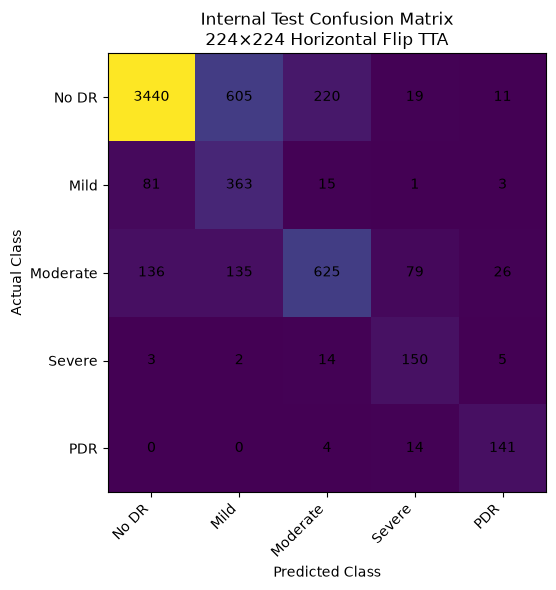

✅ TTA confusion matrix PNG saved


In [25]:
plt.figure(figsize=(7, 6))

plt.imshow(cm_tta)

plt.xticks(
    range(5),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(5),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Internal Test Confusion Matrix\n"
    "224×224 Horizontal Flip TTA"
)

for i in range(5):
    for j in range(5):
        plt.text(
            j,
            i,
            cm_tta[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    INTERNAL_TEST_DIR /
    "confusion_matrix_horizontal_flip_tta.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("✅ TTA confusion matrix PNG saved")

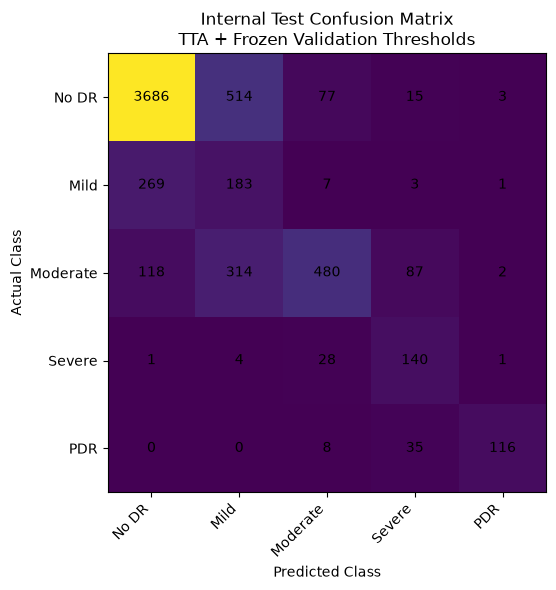

✅ Threshold confusion matrix PNG saved


In [26]:
plt.figure(figsize=(7, 6))

plt.imshow(cm_threshold)

plt.xticks(
    range(5),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(5),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Internal Test Confusion Matrix\n"
    "TTA + Frozen Validation Thresholds"
)

for i in range(5):
    for j in range(5):
        plt.text(
            j,
            i,
            cm_threshold[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    INTERNAL_TEST_DIR /
    "confusion_matrix_tta_frozen_thresholds.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("✅ Threshold confusion matrix PNG saved")

In [27]:
print("\n========================================")
print("FINAL INTERNAL TEST ARTIFACTS")
print("========================================")

for p in sorted(
    INTERNAL_TEST_DIR.rglob("*")
):
    if p.is_file():
        size_kb = p.stat().st_size / 1024

        print(
            f"{p.relative_to(INTERNAL_TEST_DIR)}"
            f"    {size_kb:.2f} KB"
        )


FINAL INTERNAL TEST ARTIFACTS
confusion_matrix_horizontal_flip_tta.csv    0.23 KB
confusion_matrix_horizontal_flip_tta.png    68.02 KB
confusion_matrix_tta_frozen_thresholds.csv    0.22 KB
confusion_matrix_tta_frozen_thresholds.png    69.96 KB
FINAL_INTERNAL_TEST_SUMMARY.txt    2.23 KB
frozen_thresholds.json    0.26 KB
test_expected_severity.npy    47.72 KB
test_horizontal_flip_tta_probabilities.npy    238.09 KB
test_strategy_comparison.csv    0.58 KB
test_threshold_predictions.npy    47.72 KB
test_true_labels.npy    47.72 KB
test_tta_predictions.npy    47.72 KB
test_tta_probabilities.npy    238.09 KB
tta_chunks\labels_0000_0250.npy    2.08 KB
tta_chunks\labels_0250_0500.npy    2.08 KB
tta_chunks\labels_0500_0750.npy    2.08 KB
tta_chunks\labels_0750_1000.npy    2.08 KB
tta_chunks\labels_1000_1250.npy    2.08 KB
tta_chunks\labels_1250_1500.npy    2.08 KB
tta_chunks\labels_1500_1750.npy    2.08 KB
tta_chunks\labels_1750_2000.npy    2.08 KB
tta_chunks\labels_2000_2250.npy    2.08 KB
tta

In [28]:
print("Number of test samples:", len(test_tta_y_true))

print(
    "TTA predictions:",
    len(test_tta_predictions)
)

print(
    "Threshold predictions:",
    len(test_threshold_predictions)
)

print(
    "TTA QWK:",
    round(test_tta_metrics["QWK"], 6)
)

print(
    "Threshold QWK:",
    round(test_threshold_metrics["QWK"], 6)
)

print("\n✅ INTERNAL TEST EVALUATION COMPLETE")

Number of test samples: 6092
TTA predictions: 6092
Threshold predictions: 6092
TTA QWK: 0.781754
Threshold QWK: 0.812089

✅ INTERNAL TEST EVALUATION COMPLETE
